## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [1]:
import pandas as pd


In [2]:
df= pd.read_csv(r"H:\My Drive\IRONHACK\WEEK_2\Day_4\archive\amz_uk_price_prediction_dataset.csv")

In [3]:
df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers



---

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?


In [4]:
#to show the columns

df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [5]:
# To count each category. The first row will be the popular catergory

category_counts = df['category'].value_counts()
print(category_counts)



category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64


In [6]:
# To have the absolute frequencies (number of listings)

category_counts.head(10)


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64

In [7]:
import matplotlib.pyplot as plt # viz
import seaborn as sns # better viz

In [8]:
# Compare categories numerically
 
category_counts.head(10).to_frame(name='Number of Listings')


,Number of Listings
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978
Manicure & Pedicure Products,18940
Skin Care,18769
Make-up,18756
Hair Care,18735


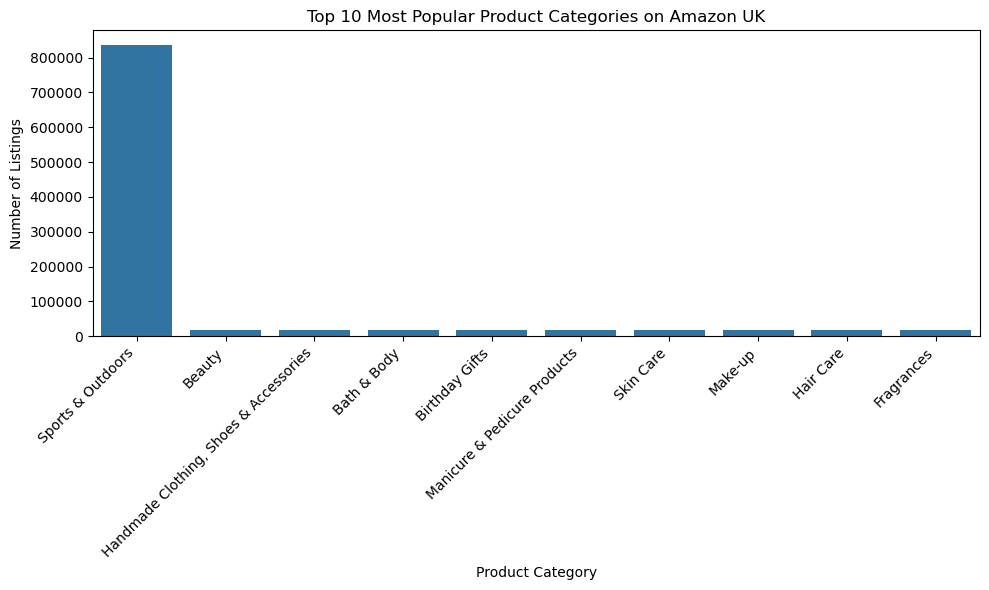

In [41]:
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    x='category',
    order=category_counts.head(10).index
)
plt.title('Top 10 Most Popular Product Categories on Amazon UK')
plt.xlabel('Product Category')
plt.ylabel('Number of Listings')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


The analysis clearly shows that the most popular product category is Sports & Outdoors, followed by Beauty, Handmade Clothing, Shoes & Accessories, Bath & Body, and Birthday Gifts, as illustrated in the bar plot.


1. **Frequency Tables**:




    - Generate a frequency table for the product `category`.
  

In [10]:
#FREQUENCY TABLE
  # show the product category and the number of listings in each category

frequency_table = df['category'].value_counts()
frequency_table


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [11]:
# just converting to a proper table

frequency_table = df['category'].value_counts().reset_index()
frequency_table.columns = ['category', 'frequency']
frequency_table

,category,frequency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
...,...,...
291,Alexa Built-In Devices,107
292,Motorbike Chassis,107
293,Plugs,107
294,Smart Home Security & Lighting,104


In [12]:
# to make the analysis stronger

frequency_table['percentage'] = (
    frequency_table['frequency'] / frequency_table['frequency'].sum()
) * 100

frequency_table


,category,frequency,percentage
0,Sports & Outdoors,836265,34.221949
1,Beauty,19312,0.790293
2,"Handmade Clothing, Shoes & Accessories",19229,0.786896
3,Bath & Body,19092,0.781290
4,Birthday Gifts,18978,0.776625
...,...,...,...
291,Alexa Built-In Devices,107,0.004379
292,Motorbike Chassis,107,0.004379
293,Plugs,107,0.004379
294,Smart Home Security & Lighting,104,0.004256


     - Which are the top 5 most listed product categories?

In [13]:
# TOP 5 PRODUTS

top_5_categories = df['category'].value_counts().head(5)

top_5_categories



category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [14]:
# to have a clean table display we convert to a DataFrame and then display it

# Create a proper table from the counts
top_5_categories = df['category'].value_counts().head(5).reset_index()
top_5_categories.columns = ['Category', 'Number of Listings']

top_5_categories  # Just this line displays it as a table


,Category,Number of Listings
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


2. **Visualizations**:

   

     - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*

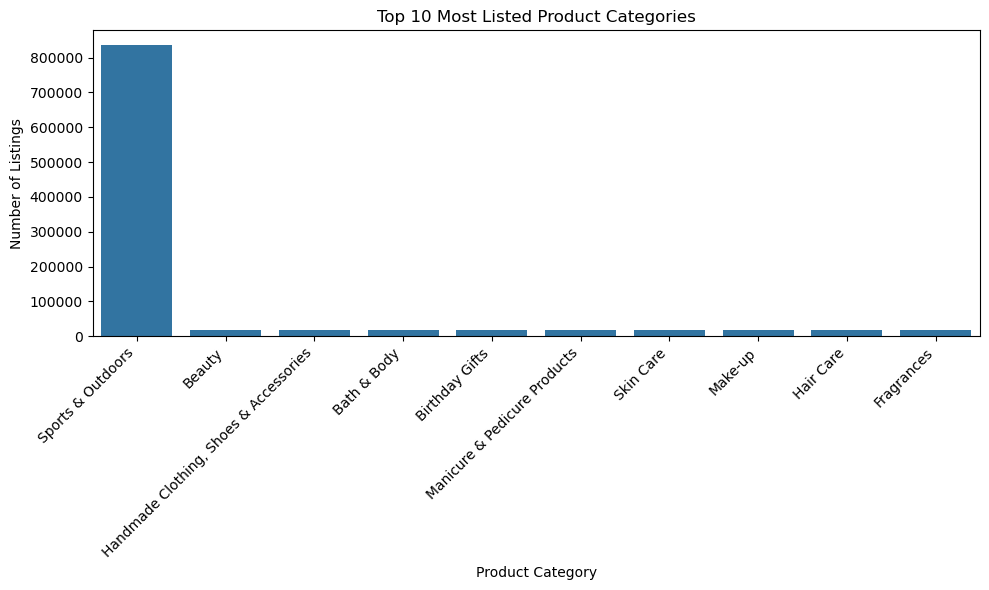

In [15]:
# Top 10 categories
top_categories = df['category'].value_counts().head(10).index

plt.figure(figsize=(10,6))
sns.countplot(
    data=df,
    x='category',
    order=top_categories
)
plt.title('Top 10 Most Listed Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Number of Listings')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


      - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [16]:
top_10_counts = df['category'].value_counts().head(10)


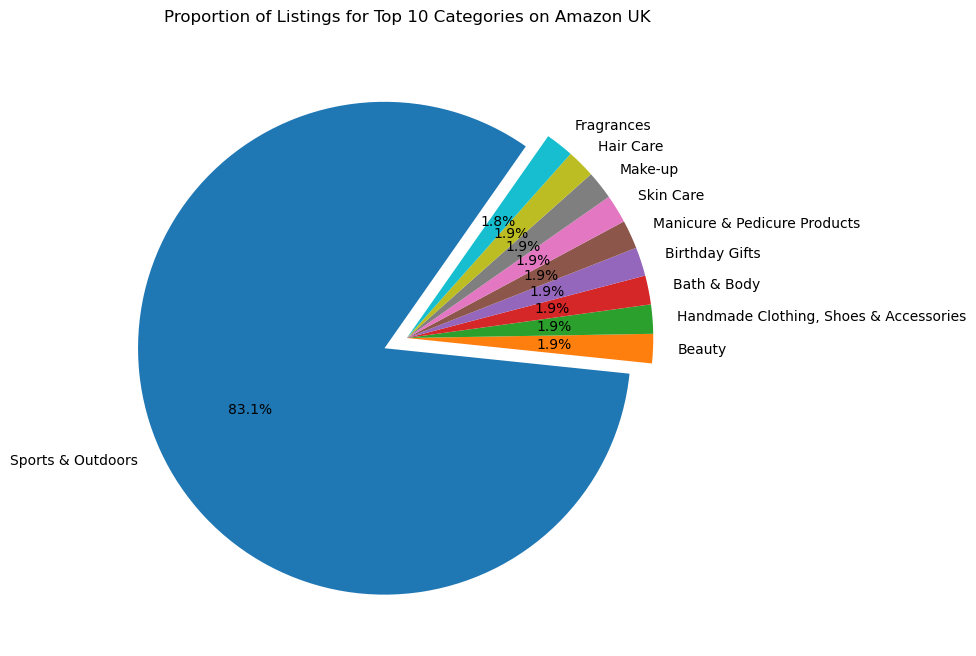

In [17]:
plt.figure(figsize=(8,8))
plt.pie(
    top_10_counts.values,       # numeric counts
    labels=top_10_counts.index, # category names
    autopct='%1.1f%%',
    startangle=55,
    explode=[0.1]+[0]*9
)
plt.title('Proportion of Listings for Top 10 Categories on Amazon UK')
plt.show()

Sports & Outdoors is the dominant product category, representing a significantly larger portion of listings compared to other top categories. This creates a skewed distribution, with the leading category clearly shaping the marketplace landscape.


---

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?



In [18]:
df['price'].describe()


count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [19]:
# to have a better ideia of the price range I need to bin the prices and count how many products fall into each bin.

# PRICE BINS DEFINITION

bins = [0, 10, 20, 50, 100, 200, 500, 1000, df['price'].max()]
labels = ['0-10','10-20','20-50','50-100','100-200','200-500','500-1000','1000+']

# CATEGORIZE EACH PRODUCT INTO A PRICE RANGE

df['price_range'] = pd.cut(df['price'], bins=bins, labels=labels, include_lowest=True)
#pd.cut 

# COUNT PRODUCTS IN EACH RANGE

price_range_counts = df['price_range'].value_counts().sort_index()
price_range_counts


price_range
0-10        633419
10-20       650324
20-50       594042
50-100      238612
100-200     133238
200-500     106511
500-1000     48391
1000+        39114
Name: count, dtype: int64

In [20]:
# OR CALCULATE PERCENTAGENS

price_range_counts = df['price_range'].value_counts().sort_index()
price_range_counts


price_range_percent = (price_range_counts / price_range_counts.sum()) * 100
price_range_percent


price_range
0-10        25.921009
10-20       26.612802
20-50       24.309609
50-100       9.764569
100-200      5.452415
200-500      4.358683
500-1000     1.980275
1000+        1.600638
Name: count, dtype: float64

C:\Users\SuzanaSouza\AppData\Local\Temp\ipykernel_11912\2333362089.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


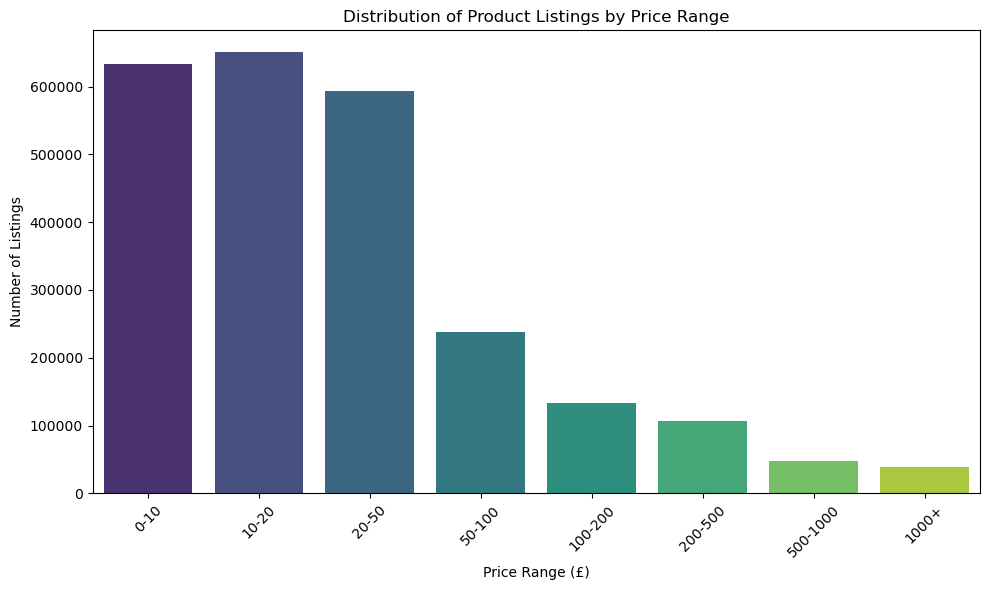

In [21]:
plt.figure(figsize=(10,6))
sns.barplot(
    x=price_range_counts.index,
    y=price_range_counts.values,
    palette="viridis"
)
plt.title('Distribution of Product Listings by Price Range')
plt.xlabel('Price Range (£)')
plt.ylabel('Number of Listings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\SuzanaSouza\AppData\Local\Temp\ipykernel_11912\754623262.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


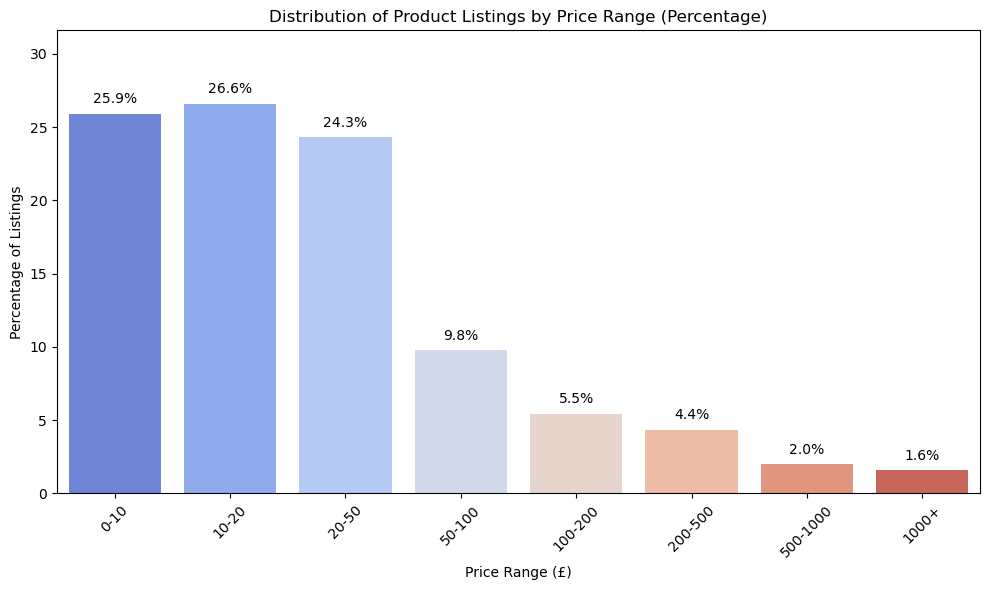

In [22]:
plt.figure(figsize=(10,6))
ax = sns.barplot(
    x=price_range_percent.index,
    y=price_range_percent.values,
    palette="coolwarm"
)

# Add percentage labels on top of bars
for i, value in enumerate(price_range_percent.values):
    ax.text(i, value + 0.5, f'{value:.1f}%', ha='center', va='bottom')

plt.title('Distribution of Product Listings by Price Range (Percentage)')
plt.xlabel('Price Range (£)')
plt.ylabel('Percentage of Listings')
plt.xticks(rotation=45)
plt.ylim(0, price_range_percent.max() + 5)  # Add some space on top
plt.tight_layout()
plt.show()

Conclusion: The majority of Amazon UK products are priced between £10 and £50, representing around 80% of listings. A small number of products exceed £200, creating a long-tail distribution that highlights a few high-priced items dominating the upper end of the marketplace.

1. **Measures of Centrality**:




    - Calculate the mean, median, and mode for the `price` of products.


In [23]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [24]:
print(f"Mean Price: £{mean_price:.2f}")
print(f"Median Price: £{median_price:.2f}")
print(f"Mode Price: £{mode_price:.2f}")

Mean Price: £89.24
Median Price: £19.09
Mode Price: £9.99


Conclusion: The mean price of products is £89.24, while the mode is £9.99. The mean is much higher than the mode because a small number of very expensive products inflate the average, creating a long-tail effect in the price distribution.

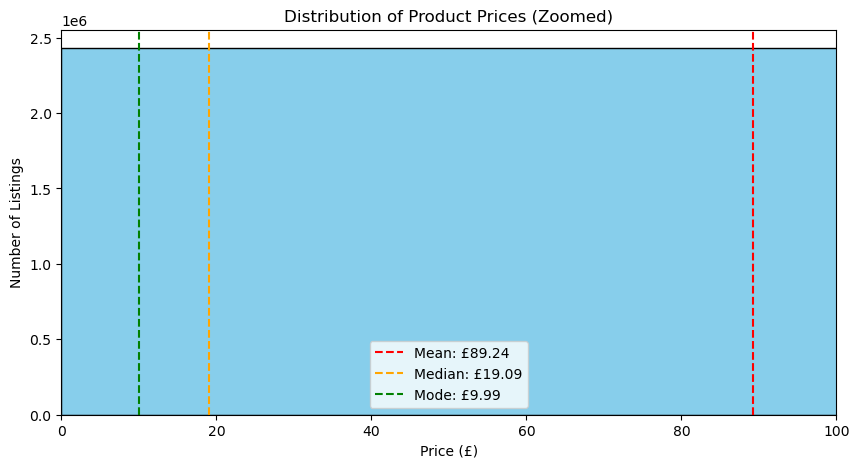

In [69]:
plt.figure(figsize=(10,5))
plt.hist(df['price'], bins=50, color='skyblue', edgecolor='black')
plt.axvline(df['price'].mean(), color='red', linestyle='--', label=f"Mean: £{df['price'].mean():.2f}")
plt.axvline(df['price'].median(), color='orange', linestyle='--', label=f"Median: £{df['price'].median():.2f}")
plt.axvline(df['price'].mode()[0], color='green', linestyle='--', label=f"Mode: £{df['price'].mode()[0]:.2f}")

plt.xlim(0, 100)  # zoom into £0–£100
plt.title('Distribution of Product Prices (Zoomed)')
plt.xlabel('Price (£)')
plt.ylabel('Number of Listings')
plt.legend()
plt.show()


This plot shows the majority of products are priced under £20, with the most common price around £10. The median price is slightly higher, at £19, indicating that half of the products are below this value. The mean price is significantly higher, at £89, because a small number of very expensive products raise the average. Overall, the distribution is heavily right-skewed, with most products at lower price points and a long tail of higher-priced items.

2. **Measures of Dispersion**:



    - Determine the variance, standard deviation, range, and interquartile range for product `price`.



In [26]:
variance_price = df['price'].var()
std_price = df['price'].std()
range_price = df['price'].max() - df['price'].min()

# Interquartile range (IQR)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

print(f"Variance: {variance_price:.2f}")
print(f"Standard Deviation: {std_price:.2f}")
print(f"Range: {range_price:.2f}")
print(f"Interquartile Range (IQR): {IQR:.2f}")

Variance: 119445.49
Standard Deviation: 345.61
Range: 100000.00
Interquartile Range (IQR): 36.00


Conclusions: 
 - A high standard deviation means prices vary widely.
 - The range will often be very large due to a few extremely expensive items.
 - The IQR shows where most product prices lie, avoiding skew from outliers.


    - How varied are the product prices? Are there any indicators of a significant spread in prices?


Product prices on Amazon UK are highly varied. Most products are inexpensive, but a few very expensive items create a long-tail distribution, leading to a large range and standard deviation. The IQR shows that the majority of products are clustered in a more moderate price span.

3. **Visualizations**:
   

     - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.


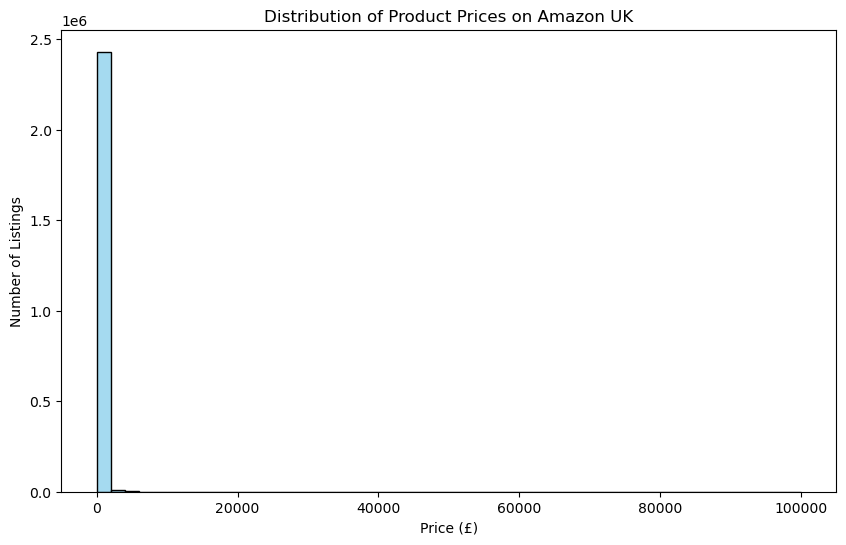

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.histplot(df['price'], bins=50, kde=False, color='skyblue')
plt.title('Distribution of Product Prices on Amazon UK')
plt.xlabel('Price (£)')
plt.ylabel('Number of Listings')
plt.show()


Amazon UK has many inexpensive items and few very expensive items. The presence of extreme outliers (luxury electronics, expensive appliances) stretches the x-axis. As a result, the bars representing the majority of products (cheap items) look compressed and small. The solution will be limit the x-axis to a more common range.

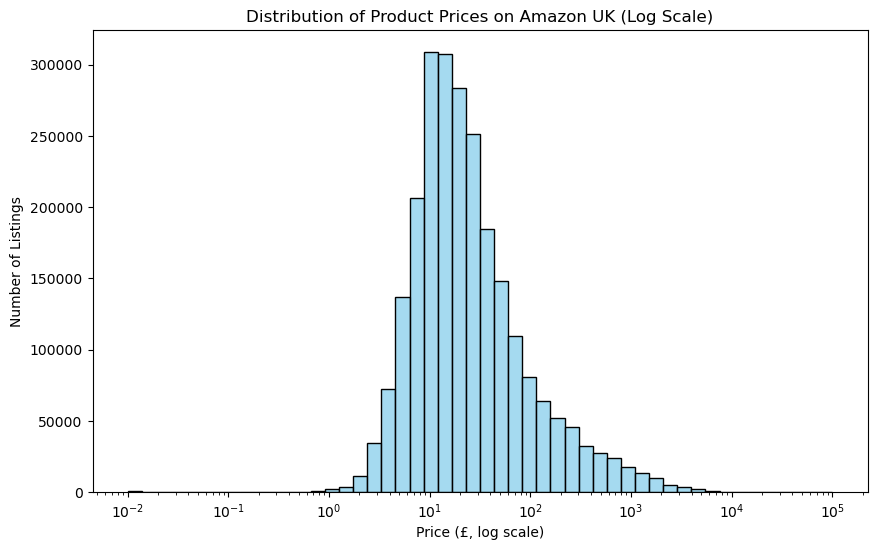

In [28]:
plt.figure(figsize=(10,6))
sns.histplot(df['price'], bins=50, kde=False, log_scale=(True, False), color='skyblue')
plt.title('Distribution of Product Prices on Amazon UK (Log Scale)')
plt.xlabel('Price (£, log scale)')
plt.ylabel('Number of Listings')
plt.show()


Most products are priced in the low-to-mid range (£0–£50). Very few products are in the high-price range (£500+), creating a long tail.

    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

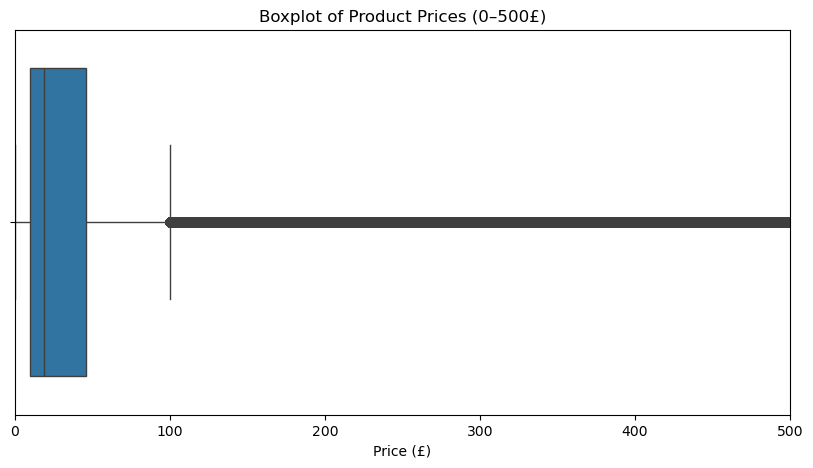

In [29]:
plt.figure(figsize=(10,5))
sns.boxplot(x=df['price'])
plt.title('Boxplot of Product Prices (0–500£)')
plt.xlabel('Price (£)')
plt.xlim(0, 500)  # focus on common price range
plt.show()

What the box plot shows?

- Most products are clustered at lower prices, as indicated by the compact box.

- The median price is well below the mean (from previous stats), showing a right-skewed distribution.

- Dots above the whiskers are the outliers — these are products priced significantly higher than the rest, e.g., high-end electronics, luxury items, or rare products.

- The long tail explains why the mean is higher than the median.

---

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?


In [30]:
df.columns


Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category', 'price_range'],
      dtype='object')

In [31]:
df['reviews'].describe()


count    2.443651e+06
mean     4.806278e+02
std      5.944124e+03
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      5.900000e+01
max      1.356658e+06
Name: reviews, dtype: float64

In [32]:
review_counts = df['reviews']

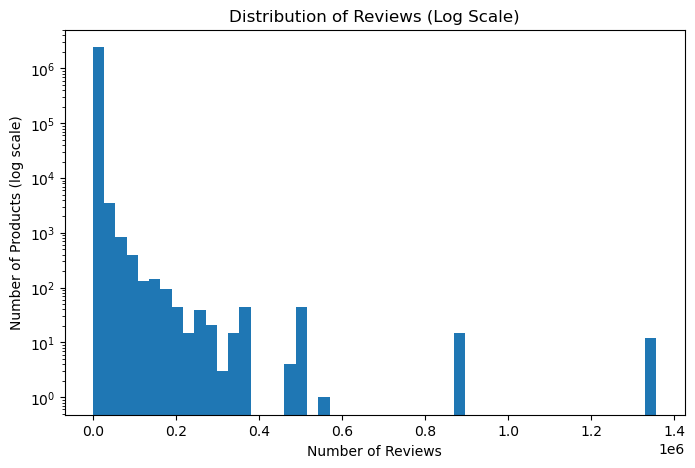

In [33]:
plt.figure(figsize=(8,5))
plt.hist(review_counts, bins=50)
plt.yscale('log')
plt.title('Distribution of Reviews (Log Scale)')
plt.xlabel('Number of Reviews')
plt.ylabel('Number of Products (log scale)')
plt.show()

Most products have very few reviews (often under 10)
A small fraction of products dominates customer attention
Review counts show a long-tail distribution
This suggests:
   - Market concentration
   - A few popular products receive most engagement

In [34]:
# TO SEE BETTER WE CAN SEPARATE THE PRODUCTS IN RANGES OF VALUES

In [35]:
bins = [0, 1, 5, 10, 50, 100, 500, 1000, df['reviews'].max()]
labels = ['0', '1–5', '6–10', '11–50', '51–100', '101–500', '501–1000', '1000+']

review_ranges = pd.cut(df['reviews'], bins=bins, labels=labels, right=False)
review_range_counts = review_ranges.value_counts().sort_index()

review_range_counts


reviews
0           1225641
1–5          215127
6–10          98651
11–50        261383
51–100       123399
101–500      263069
501–1000      90167
1000+        166203
Name: count, dtype: int64

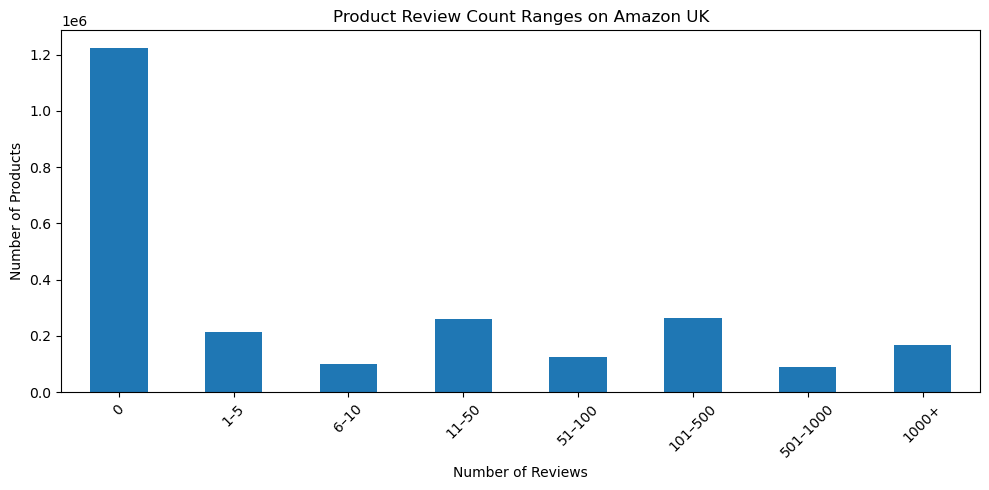

In [36]:
plt.figure(figsize=(10,5))
review_range_counts.plot(kind='bar')
plt.title('Product Review Count Ranges on Amazon UK')
plt.xlabel('Number of Reviews')
plt.ylabel('Number of Products')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Conclusion of the analysis:

Customer engagement on Amazon UK is highly uneven.
Most products receive very few reviews, while a small number of popular products accumulate hundreds or thousands of reviews. This long-tail pattern indicates that visibility and popularity play a major role in customer interaction.


1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?



In [45]:
df.columns


Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category', 'price_range'],
      dtype='object')

In [46]:
# Mean star rating
mean_stars = df['stars'].mean()

# Median star rating
median_stars = df['stars'].median()

# Mode star rating (most common rating)
mode_stars = df['stars'].mode()[0]

print(f"Mean rating (stars): {mean_stars:.2f}")
print(f"Median rating (stars): {median_stars:.2f}")
print(f"Mode rating (stars): {mode_stars}")


Mean rating (stars): 2.15
Median rating (stars): 0.00
Mode rating (stars): 0.0


There is a huge number of 0-star entries, It likely means “no rating available” or “not yet rated”. So the numbers do not reflect customer opinion, but data availability.
Fewer products with 1–5 stars

In [47]:
df['stars'].value_counts().sort_index()

stars
0.0    1225641
1.0       8484
1.1          3
1.2         23
1.3         78
1.4        149
1.5        404
1.6        147
1.7        177
1.8        249
1.9        300
2.0       3901
2.1        540
2.2        602
2.3        734
2.4       1060
2.5       2103
2.6       1579
2.7       2104
2.8       2306
2.9       3341
3.0      12819
3.1       4679
3.2       5771
3.3       8269
3.4      10355
3.5      14673
3.6      16219
3.7      21137
3.8      27876
3.9      36555
4.0      66089
4.1      65115
4.2      86871
4.3     112564
4.4     136165
4.5     151577
4.6     136995
4.7      94566
4.8      41858
4.9      11081
5.0     128492
Name: count, dtype: int64

As there is to many unrated products, we can see a different value for mean, media and mode rating if we separete the rated produts from the unrated ones. This will gives us better analysis approach.

In [ ]:
#Separate rated vs unrated products
rated_products = df[df['stars'] > 0]


In [54]:
rated_products['stars'].describe()

count    1.218010e+06
mean     4.319161e+00
std      5.552868e-01
min      1.000000e+00
25%      4.100000e+00
50%      4.400000e+00
75%      4.600000e+00
max      5.000000e+00
Name: stars, dtype: float64

In [53]:
mean_stars = rated_products['stars'].mean()
median_stars = rated_products['stars'].median()
mode_stars = rated_products['stars'].mode()[0]

print(f"Mean rating (stars): {mean_stars:.2f}")
print(f"Median rating (stars): {median_stars:.2f}")
print(f"Mode rating (stars): {mode_stars}")


Mean rating (stars): 4.32
Median rating (stars): 4.40
Mode rating (stars): 4.5


A significant portion of products in the dataset have a star value of 0, indicating that they have not yet been rated. When considering only rated products, customer ratings display a strong positive trend. Most products receive ratings between 4 and 5 stars, with 5.0 being the most common rating. Low ratings are relatively rare, suggesting that reviewed products generally enjoy high customer satisfaction on Amazon UK

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?


In [58]:
# Variance
variance_all = df['stars'].var()

# Standard deviation
std_all = df['stars'].std()

# Interquartile Range (IQR)
Q1_all = df['stars'].quantile(0.25)
Q3_all = df['stars'].quantile(0.75)
IQR_all = Q3_all - Q1_all

print("INCLUDING unrated products (stars = 0)")
print(f"Variance: {variance_all:.2f}")
print(f"Standard Deviation: {std_all:.2f}")
print(f"IQR: {IQR_all:.2f}")

INCLUDING unrated products (stars = 0)
Variance: 4.82
Standard Deviation: 2.19
IQR: 4.40


Including unrated products leads to an apparently high dispersion in ratings. However, this variability is largely driven by missing rating values rather than true differences in customer sentiment. Therefore, excluding unrated products is necessary to obtain a more accurate assessment of customer ratings.

In [ ]:
rated_products = df[df['stars'] > 0]

variance_rated = rated_products['stars'].var()
std_rated = rated_products['stars'].std()

Q1_rated = rated_products['stars'].quantile(0.25)
Q3_rated = rated_products['stars'].quantile(0.75)
IQR_rated = Q3_rated - Q1_rated

print("\nEXCLUDING unrated products (stars > 0)")
print(f"Variance: {variance_rated:.2f}")
print(f"Standard Deviation: {std_rated:.2f}")
print(f"IQR: {IQR_rated:.2f}")


EXCLUDING unrated products (stars > 0)
Variance: 0.31
Standard Deviation: 0.56
IQR: 0.50


After excluding unrated products, the variance, standard deviation, and interquartile range decrease substantially, indicating a much lower dispersion in customer ratings. The low variance confirms that ratings are tightly clustered, while the standard deviation shows that ratings typically deviate by less than one star from the mean. Additionally, the interquartile range demonstrates that the middle 50% of ratings fall within a half-star range.

Overall, this indicates that most customers rate products between 4 and 5 stars, with little disagreement among reviewers. These results suggest that customer ratings on Amazon UK are highly consistent and concentrated in a narrow, high-rating range, reflecting generally positive customer sentiment.


3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?


In [61]:
# Including unrated products
skew_all = skew(df['stars'])
kurt_all = kurtosis(df['stars'])

print("Including unrated products (stars = 0)")
print(f"Skewness: {skew_all:.2f}")
print(f"Kurtosis: {kurt_all:.2f}")


Including unrated products (stars = 0)
Skewness: 0.08
Kurtosis: -1.93


Skewness close to 0 shows the distribution is almost symmetric, because there is a huge spike at 0 (over 1.2 million products)

The rest of the ratings (1–5) are a very small portion. Mathematically, this produces a large spike at 0, which balances the tail to make skewness appear low.

Negative kurtosis → platykurtic (flatter than normal). The large 0 spike flattens the peak of the rest of the data. The distribution has light tails and a flat peak, which is misleading

Conclusion: Including unrated products distorts all shape metrics. The skewness and kurtosis do not reflect real customer ratings. These numbers cannot be used to judge customer tendencies reliably.

In [62]:
# Calculate for rated products only (stars > 0)

rated_products = df[df['stars'] > 0]

skew_rated = skew(rated_products['stars'])
kurt_rated = kurtosis(rated_products['stars'])

print("\nExcluding unrated products (stars > 0)")
print(f"Skewness: {skew_rated:.2f}")
print(f"Kurtosis: {kurt_rated:.2f}")



Excluding unrated products (stars > 0)
Skewness: -2.38
Kurtosis: 9.78


Negative skew or left-skewed occurs when the tail is on the lower end. This makes sense, as most ratings cluster at high values (4–5 stars) and a smaller number of products have lower ratings (1–3 stars)
In other words: ratings are biased toward higher values, with few low ratings

Positive kurtosis or leptokurtic, shows a very sharp peak in the distribution. Most ratings are tightly concentrated around 4–5 stars, with a long “tail” toward lower ratings
This confirms strong consistency in high ratings, with few outliers

When unrated products are included, the skewness is near zero and kurtosis is negative, which gives a misleading impression of symmetry and low peakedness. After excluding unrated products, ratings are strongly left-skewed with high kurtosis, indicating that most products receive high ratings (4–5 stars) while only a few products are rated lower. This confirms that customer feedback on Amazon UK is generally positive and highly concentrated around high ratings.


4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

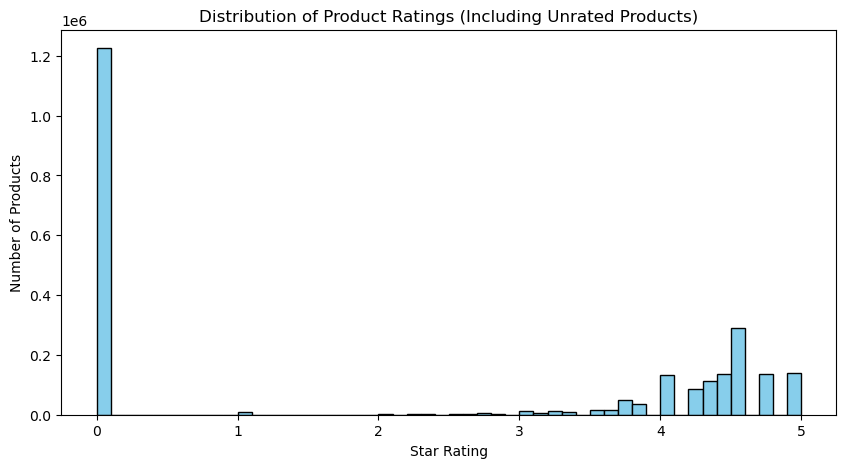

In [65]:
#Histogram including unrated products

plt.figure(figsize=(10,5))
plt.hist(df['stars'], bins=50, color='skyblue', edgecolor='black')
plt.title('Distribution of Product Ratings (Including Unrated Products)')
plt.xlabel('Star Rating')
plt.ylabel('Number of Products')
plt.show()


---

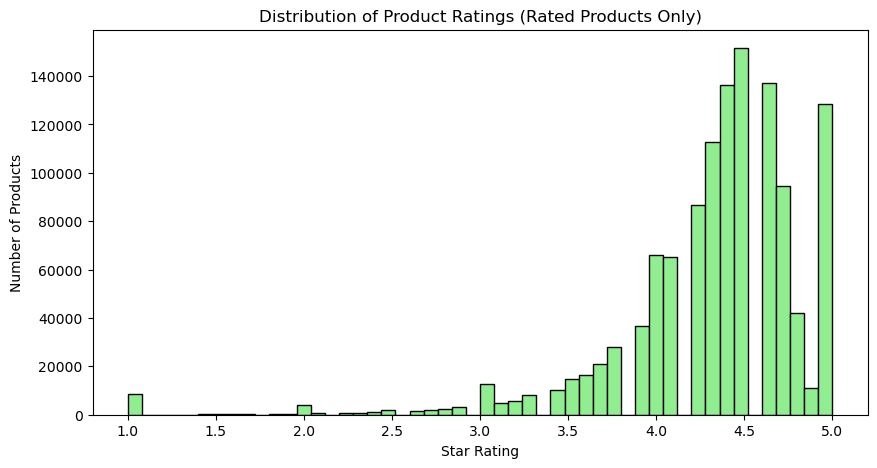

In [66]:
#Histogram excluding unrated products

rated_products = df[df['stars'] > 0]

plt.figure(figsize=(10,5))
plt.hist(rated_products['stars'], bins=50, color='lightgreen', edgecolor='black')
plt.title('Distribution of Product Ratings (Rated Products Only)')
plt.xlabel('Star Rating')
plt.ylabel('Number of Products')
plt.show()


The histogram of rated products shows that most ratings fall between 4 and 5 stars, with 5 stars being the most frequent. Low ratings are relatively rare. Including unrated products (0 stars) creates a large spike at zero that obscures the true distribution of customer feedback. Overall, this confirms that customers generally rate products positively on Amazon UK.

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 